# Caso de estudio 1: datos que merezcan confianza
## Entrega final. Curación, contrato y controles

**Equipo 6:** Bruno Fidalgo y Juan Pablo Esteva

Este notebook continúa `01_avance_olist.ipynb`. La exploración y el diagnóstico inicial están ahí; acá se construye la versión curada, su contrato y los controles, y se responden los comentarios de la devolución del avance.

**Cómo reproducir**

1. `pip install -r requirements.txt`
2. Descargar el ZIP desde https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce y descomprimir los 9 CSV en `data/raw/`.
3. Ejecutar todas las celdas en orden desde la carpeta `notebooks/`.

En Google Colab: clonar el repositorio, subir los 9 CSV a `data/raw/` (o bajarlos con la API de Kaggle) y ejecutar desde `notebooks/`:

```
!git clone https://github.com/Juan03-e/olist-ingdatos.git olist-ingdatos
%cd olist-ingdatos/notebooks
!pip install -q -r ../requirements.txt
```

**Salidas:** `data/curated/pedidos.parquet` (una fila por pedido), `data/curated/items.parquet` (una fila por ítem), `reports/perfil_antes_despues.csv`, `reports/log_curacion.csv`, `reports/filas_afectadas.csv` y `reports/desafio_controles.csv`. Los CSV de `data/raw/` nunca se modifican.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.contratos import validar, exigir, ESTADOS_PEDIDO, LAT_BRASIL, LNG_BRASIL

RUTA_RAW = "../data/raw/"
RUTA_CURATED = "../data/curated/"
RUTA_REPORTS = "../reports/"
RUTA_FIGS = "../reports/figs/"
for ruta in [RUTA_CURATED, RUTA_FIGS]:
    os.makedirs(ruta, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

## 1. Qué cambia respecto del avance

| Comentario de la devolución | Dónde se resuelve |
|---|---|
| D05: mostrar cuánto cambia el promedio según la regla elegida para las reseñas repetidas | Sección 3 |
| Contrato con Pandera | `src/contratos.py` y sección 6 |
| Reglas del perfil como controles que fallan | Secciones 2 y 6 (`exigir` lanza un error) |
| Comparación antes/después con las filas afectadas | Sección 7 |
| Desafío con al menos tres reglas violadas | Sección 9 |
| Reglas nuevas: fecha límite fuera de rango y no entregado con fecha de entrega | Sección 2 |
| Integrar sellers y geolocation | Secciones 4 y 5 |
| Responder P3 | Sección 8 |

## 2. Carga y perfil de calidad reproducible

La carga convierte las fechas y **falla** si algún valor no se puede convertir, en lugar de dejarlo nulo en silencio (D03). El perfil es una función: se ejecuta igual sobre los datos crudos y sobre los curados, y eso permite la comparación de la sección 7.

Cada regla cuenta las filas con problema. Si la versión curada tiene una columna indicadora para esa regla, también cuenta cuántas quedaron **sin marcar**. Estados: `OK` (dentro del umbral), `MARCADO` (todas las filas con problema tienen su indicador) y `REVISAR`.

In [2]:
FECHAS = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "items": ["shipping_limit_date"],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
}


def cargar_crudos():
    t = {
        "orders": pd.read_csv(RUTA_RAW + "olist_orders_dataset.csv"),
        "items": pd.read_csv(RUTA_RAW + "olist_order_items_dataset.csv"),
        "payments": pd.read_csv(RUTA_RAW + "olist_order_payments_dataset.csv"),
        "reviews": pd.read_csv(RUTA_RAW + "olist_order_reviews_dataset.csv"),
        "customers": pd.read_csv(RUTA_RAW + "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str}),
        "products": pd.read_csv(RUTA_RAW + "olist_products_dataset.csv"),
        "sellers": pd.read_csv(RUTA_RAW + "olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str}),
        "geolocation": pd.read_csv(RUTA_RAW + "olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str}),
        "translation": pd.read_csv(RUTA_RAW + "product_category_name_translation.csv"),
    }
    for tabla, columnas in FECHAS.items():
        for col in columnas:
            nulos = t[tabla][col].isna().sum()
            t[tabla][col] = pd.to_datetime(t[tabla][col], errors="coerce")
            assert t[tabla][col].isna().sum() == nulos, f"{tabla}.{col}: hay fechas que no se pudieron convertir"
    return t


crudos = cargar_crudos()
COLUMNAS = {nombre: list(df.columns) for nombre, df in crudos.items()}
pd.DataFrame({nombre: {"filas": len(df), "columnas": df.shape[1]} for nombre, df in crudos.items()}).T

,filas,columnas
orders,99441,8
items,112650,7
payments,103886,5
reviews,99224,7
customers,99441,5
products,32951,9
sellers,3095,4
geolocation,1000163,5
translation,71,2


In [3]:
def perfil(t):
    filas = []
    o, i, p, rv = t["orders"], t["items"], t["payments"], t["reviews"]
    c, pr, s, g, tr = t["customers"], t["products"], t["sellers"], t["geolocation"], t["translation"]

    def r(dim, tabla, regla, problema, umbral=0, marca=None):
        df = t[tabla]
        n = len(problema)
        casos = int(problema.sum())
        sin_marca = casos
        if marca is not None and marca in df.columns:
            sin_marca = int((problema & ~df.loc[problema.index, marca]).sum())
        pct = casos / n * 100 if n else 0
        if pct <= umbral:
            estado = "OK"
        elif sin_marca == 0:
            estado = "MARCADO"
        else:
            estado = "REVISAR"
        filas.append({"dimensión": dim, "tabla": tabla, "regla": regla, "evaluadas": n, "casos": casos,
                      "sin_marcar": sin_marca, "pct": round(pct, 2), "umbral_pct": umbral, "estado": estado})

    r("unicidad", "orders", "order_id no se repite", o["order_id"].duplicated())
    r("unicidad", "items", "order_id + order_item_id no se repite", i.duplicated(["order_id", "order_item_id"]))
    r("unicidad", "payments", "order_id + payment_sequential no se repite", p.duplicated(["order_id", "payment_sequential"]))
    r("unicidad", "reviews", "review_id no se repite", rv["review_id"].duplicated(), marca="review_id_compartido")
    r("unicidad", "reviews", "review_id + order_id no se repite", rv.duplicated(["review_id", "order_id"]))
    r("unicidad", "customers", "customer_id no se repite", c["customer_id"].duplicated())
    r("unicidad", "products", "product_id no se repite", pr["product_id"].duplicated())
    r("unicidad", "sellers", "seller_id no se repite", s["seller_id"].duplicated())
    for nombre in t:
        r("unicidad", nombre, "no hay filas completamente repetidas", t[nombre][COLUMNAS[nombre]].duplicated())

    for nombre in t:
        for col in COLUMNAS[nombre]:
            if t[nombre][col].isna().any():
                marca = "sin_categoria" if col.startswith("product_") and nombre == "products" else None
                r("completitud", nombre, f"{col} no es nulo", t[nombre][col].isna(), umbral=5, marca=marca)

    r("validez", "items", "price > 0", i["price"] <= 0)
    r("validez", "items", "freight_value >= 0", i["freight_value"] < 0)
    r("validez", "reviews", "review_score entre 1 y 5", ~rv["review_score"].between(1, 5))
    r("validez", "payments", "payment_value > 0", p["payment_value"] <= 0, marca="pago_cero")
    r("validez", "payments", "payment_installments >= 1", p["payment_installments"] < 1)
    con_peso = pr["product_weight_g"].notna()
    r("validez", "products", "product_weight_g > 0", pr.loc[con_peso, "product_weight_g"] <= 0)
    r("validez", "customers", "prefijo CEP de 5 dígitos", c["customer_zip_code_prefix"].str.len() != 5)
    r("validez", "sellers", "prefijo CEP de 5 dígitos", s["seller_zip_code_prefix"].str.len() != 5)
    r("validez", "orders", "order_status es un estado conocido", ~o["order_status"].isin(ESTADOS_PEDIDO))
    fuera = ~(g["geolocation_lat"].between(*LAT_BRASIL) & g["geolocation_lng"].between(*LNG_BRASIL))
    r("validez", "geolocation", "la coordenada cae dentro de Brasil", fuera, marca="fuera_de_brasil")
    r("validez", "items", "shipping_limit_date no posterior a la última compra",
      i["shipping_limit_date"] > o["order_purchase_timestamp"].max(), marca="limite_envio_invalido")

    ambas = o["order_purchase_timestamp"].notna() & o["order_approved_at"].notna()
    r("consistencia", "orders", "compra <= aprobación",
      o.loc[ambas, "order_purchase_timestamp"] > o.loc[ambas, "order_approved_at"])
    ambas = o["order_delivered_carrier_date"].notna() & o["order_delivered_customer_date"].notna()
    r("consistencia", "orders", "entrega al transportista <= entrega al cliente",
      o.loc[ambas, "order_delivered_carrier_date"] > o.loc[ambas, "order_delivered_customer_date"],
      marca="transportista_despues_cliente")
    entregado = o["order_status"] == "delivered"
    r("consistencia", "orders", "si está delivered, tiene fecha de entrega",
      o.loc[entregado, "order_delivered_customer_date"].isna(), marca="delivered_sin_fecha")
    r("consistencia", "orders", "si está delivered, tiene aprobación",
      o.loc[entregado, "order_approved_at"].isna(), marca="delivered_sin_aprobacion")
    r("consistencia", "orders", "si no está delivered, no tiene fecha de entrega",
      o.loc[~entregado, "order_delivered_customer_date"].notna(), marca="no_entregado_con_fecha")
    total_items = i.groupby("order_id")[["price", "freight_value"]].sum().sum(axis=1)
    total_pagos = p.groupby("order_id")["payment_value"].sum()
    distinto = ((total_pagos - total_items).dropna().abs() > 1)
    con_ambos = o["order_id"].isin(distinto.index)
    r("consistencia", "orders", "lo pagado coincide con precio + flete (±1 BRL)",
      o.loc[con_ambos, "order_id"].map(distinto), umbral=1, marca="pago_distinto_items")

    r("integridad", "items", "order_id existe en orders", ~i["order_id"].isin(o["order_id"]))
    r("integridad", "payments", "order_id existe en orders", ~p["order_id"].isin(o["order_id"]))
    r("integridad", "reviews", "order_id existe en orders", ~rv["order_id"].isin(o["order_id"]))
    r("integridad", "orders", "customer_id existe en customers", ~o["customer_id"].isin(c["customer_id"]))
    r("integridad", "items", "product_id existe en products", ~i["product_id"].isin(pr["product_id"]))
    r("integridad", "items", "seller_id existe en sellers", ~i["seller_id"].isin(s["seller_id"]))
    con_cat = pr["product_category_name"].notna()
    r("integridad", "products", "la categoría tiene traducción",
      ~pr.loc[con_cat, "product_category_name"].isin(tr["product_category_name"]))
    prefijos = set(g.loc[~fuera, "geolocation_zip_code_prefix"])
    r("integridad", "customers", "el prefijo CEP tiene coordenadas",
      ~c["customer_zip_code_prefix"].isin(prefijos), marca="sin_coordenadas")
    r("integridad", "sellers", "el prefijo CEP tiene coordenadas",
      ~s["seller_zip_code_prefix"].isin(prefijos), marca="sin_coordenadas")

    r("cobertura", "orders", "el pedido tiene ítems", ~o["order_id"].isin(i["order_id"]), marca="sin_items")
    r("cobertura", "orders", "el pedido tiene pagos", ~o["order_id"].isin(p["order_id"]), marca="sin_pago")
    r("cobertura", "orders", "el pedido tiene reseña", ~o["order_id"].isin(rv["order_id"]), marca="sin_resena")
    return pd.DataFrame(filas)


perfil_antes = perfil(crudos)
print(len(perfil_antes), "reglas")
print(perfil_antes["estado"].value_counts())
perfil_antes[perfil_antes["estado"] != "OK"]

59 reglas
estado
OK         40
REVISAR    19
Name: count, dtype: int64


,dimensión,tabla,regla,evaluadas,casos,sin_marcar,pct,umbral_pct,estado
3,unicidad,reviews,review_id no se repite,99224,814,814,0.82,0,REVISAR
15,unicidad,geolocation,no hay filas completamente repetidas,1000163,261831,261831,26.18,0,REVISAR
20,completitud,reviews,review_comment_title no es nulo,99224,87656,87656,88.34,5,REVISAR
21,completitud,reviews,review_comment_message no es nulo,99224,58247,58247,58.70,5,REVISAR
33,validez,payments,payment_value > 0,103886,9,9,0.01,0,REVISAR
34,validez,payments,payment_installments >= 1,103886,2,2,0.00,0,REVISAR
35,validez,products,product_weight_g > 0,32949,4,4,0.01,0,REVISAR
39,validez,geolocation,la coordenada cae dentro de Brasil,1000163,42,42,0.00,0,REVISAR
40,validez,items,shipping_limit_date no posterior a la última c...,112650,4,4,0.00,0,REVISAR
42,consistencia,orders,entrega al transportista <= entrega al cliente,96475,23,23,0.02,0,REVISAR


Respecto del avance se agregaron siete reglas: las dos que habíamos anotado (fecha límite de envío posterior a la última compra y pedido no entregado con fecha de entrega), la clave `review_id + order_id`, `delivered` sin aprobación, y las de `sellers` y `geolocation` (unicidad de `seller_id`, `seller_id` existe, coordenadas dentro de Brasil y prefijos con coordenadas).

## 3. D05 revisada: ¿cuánto cambia el puntaje según la regla para reseñas repetidas?

547 pedidos tienen 2 o 3 reseñas y 202 de ellos con puntajes distintos. Comparamos cinco reglas posibles sobre el promedio general y sobre la diferencia a tiempo/tarde, que es lo que usa P2.

In [4]:
rv = crudos["reviews"].sort_values(["review_creation_date", "review_answer_timestamp"])
o = crudos["orders"]
entregado = o[(o["order_status"] == "delivered") & o["order_delivered_customer_date"].notna()].copy()
entregado["tarde"] = (entregado["order_delivered_customer_date"] - entregado["order_estimated_delivery_date"]).dt.days > 0

por_pedido = rv.groupby("order_id")["review_score"]
distintos = por_pedido.nunique() > 1
reglas_resena = {
    "más reciente (elegida)": rv.drop_duplicates("order_id", keep="last").set_index("order_id")["review_score"],
    "más antigua": rv.drop_duplicates("order_id", keep="first").set_index("order_id")["review_score"],
    "promedio de las reseñas": por_pedido.mean(),
    "peor puntaje": por_pedido.min(),
    "excluir pedidos con puntajes distintos": por_pedido.first()[~distintos],
}

filas = []
for nombre, puntaje in reglas_resena.items():
    e = entregado.assign(score=entregado["order_id"].map(puntaje)).dropna(subset=["score"])
    filas.append({"regla": nombre, "pedidos con puntaje": len(puntaje), "promedio general": puntaje.mean(),
                  "a tiempo": e.loc[~e["tarde"], "score"].mean(), "tarde": e.loc[e["tarde"], "score"].mean()})
sensibilidad = pd.DataFrame(filas)
sensibilidad["diferencia a tiempo - tarde"] = sensibilidad["a tiempo"] - sensibilidad["tarde"]
sensibilidad.round(3)

,regla,pedidos con puntaje,promedio general,a tiempo,tarde,diferencia a tiempo - tarde
0,más reciente (elegida),98673,4.086,4.290,2.271,2.019
1,más antigua,98673,4.087,4.291,2.273,2.018
2,promedio de las reseñas,98673,4.087,4.291,2.272,2.019
3,peor puntaje,98673,4.085,4.289,2.270,2.019
4,excluir pedidos con puntajes distintos,98471,4.088,4.292,2.271,2.021


In [5]:
print("Pedidos con varias reseñas y la misma fecha de creación:",
      rv[rv["order_id"].duplicated(keep=False)].duplicated(["order_id", "review_creation_date"], keep=False).groupby(rv["order_id"]).any().sum())

Pedidos con varias reseñas y la misma fecha de creación: 157


**Interpretación:** la regla elegida casi no cambia los resultados. El promedio general va de 4,085 (peor puntaje) a 4,088 (excluir los 202 pedidos), y la diferencia entre pedidos a tiempo y tarde, que es lo que sostiene P2, se mantiene entre 2,018 y 2,021 puntos con cualquier regla. Hay 157 pedidos con varias reseñas creadas el mismo día; en esos casos desempatamos por `review_answer_timestamp`. **Decisión:** D05 pasa a firme con la reseña más reciente, porque refleja la última opinión del cliente y conserva los 98.673 pedidos con reseña. **Qué no podemos concluir:** cuál de las reseñas repetidas es la "verdadera"; solo que la elección no cambia las conclusiones de P2.

## 4. Curación

Se trabaja sobre una copia de cada tabla. Las correcciones se limitan a valores que son inválidos con certeza; el resto se **marca** con columnas indicadoras. Cada decisión queda en el log de la sección 7.

In [6]:
cur = {nombre: df.copy() for nombre, df in crudos.items()}
o, i, p, rv = cur["orders"], cur["items"], cur["payments"], cur["reviews"]
c, pr, s, g = cur["customers"], cur["products"], cur["sellers"], cur["geolocation"]

entregado = o["order_status"] == "delivered"
o["transportista_despues_cliente"] = o["order_delivered_carrier_date"] > o["order_delivered_customer_date"]
o["delivered_sin_fecha"] = entregado & o["order_delivered_customer_date"].isna()
o["delivered_sin_aprobacion"] = entregado & o["order_approved_at"].isna()
o["no_entregado_con_fecha"] = ~entregado & o["order_delivered_customer_date"].notna()
o["sin_items"] = ~o["order_id"].isin(i["order_id"])
o["sin_pago"] = ~o["order_id"].isin(p["order_id"])
o["sin_resena"] = ~o["order_id"].isin(rv["order_id"])
total_items = i.groupby("order_id")[["price", "freight_value"]].sum().sum(axis=1)
total_pagos = p.groupby("order_id")["payment_value"].sum()
o["pago_distinto_items"] = o["order_id"].map((total_pagos - total_items).abs() > 1).astype("boolean").fillna(False).astype(bool)
o["en_periodo_mensual"] = o["order_purchase_timestamp"].between("2017-01-01", "2018-08-31 23:59:59")

i["limite_envio_invalido"] = i["shipping_limit_date"] > o["order_purchase_timestamp"].max()
i.loc[i["limite_envio_invalido"], "shipping_limit_date"] = pd.NaT

p["pago_cero"] = p["payment_value"] <= 0
p["cuotas_corregidas"] = p["payment_installments"] < 1
p.loc[p["cuotas_corregidas"], "payment_installments"] = 1

rv["review_id_compartido"] = rv["review_id"].duplicated(keep=False)
rv["elegida"] = ~rv.sort_values(["review_creation_date", "review_answer_timestamp"]).duplicated("order_id", keep="last").reindex(rv.index)

pr["peso_invalido"] = pr["product_weight_g"] <= 0
pr.loc[pr["peso_invalido"], "product_weight_g"] = np.nan
traduccion = pd.concat([cur["translation"], pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers"],
})], ignore_index=True)
cur["translation"] = traduccion
pr["categoria"] = pr["product_category_name"].map(traduccion.set_index("product_category_name")["product_category_name_english"])
pr["sin_categoria"] = pr["categoria"].isna()
pr["categoria"] = pr["categoria"].fillna("sin_categoria")

g["fuera_de_brasil"] = ~(g["geolocation_lat"].between(*LAT_BRASIL) & g["geolocation_lng"].between(*LNG_BRASIL))
geo_prefijo = (g[~g["fuera_de_brasil"]].groupby("geolocation_zip_code_prefix")
               .agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median"),
                    n_puntos=("geolocation_lat", "size"), n_estados=("geolocation_state", "nunique")))
c["sin_coordenadas"] = ~c["customer_zip_code_prefix"].isin(geo_prefijo.index)
s["sin_coordenadas"] = ~s["seller_zip_code_prefix"].isin(geo_prefijo.index)

print("Prefijos con coordenadas:", len(geo_prefijo), "| puntos fuera de Brasil descartados:", g["fuera_de_brasil"].sum(),
      "| prefijos con puntos en más de un estado:", (geo_prefijo["n_estados"] > 1).sum())

Prefijos con coordenadas: 19010 | puntos fuera de Brasil descartados: 42 | prefijos con puntos en más de un estado: 8


**Por qué la mediana por prefijo.** `geolocation` tiene 1.000.163 filas para 19.015 prefijos y no tiene clave: un prefijo de CEP cubre una zona, no un punto. La mediana es robusta a los puntos mal ubicados que quedan dentro de Brasil. Antes de agregar se descartan los puntos fuera del rectángulo de Brasil (latitud −33,75 a 5,30; longitud −73,99 a −34,79), que con la media moverían el centro cientos de kilómetros.

In [7]:
g_lejos = g[~g["fuera_de_brasil"]].merge(geo_prefijo, left_on="geolocation_zip_code_prefix", right_index=True)
dlat = np.radians(g_lejos["geolocation_lat"] - g_lejos["lat"])
dlng = np.radians(g_lejos["geolocation_lng"] - g_lejos["lng"])
a = np.sin(dlat / 2) ** 2 + np.cos(np.radians(g_lejos["lat"])) * np.cos(np.radians(g_lejos["geolocation_lat"])) * np.sin(dlng / 2) ** 2
g_lejos["km_a_mediana"] = 6371 * 2 * np.arcsin(np.sqrt(a))
print(g_lejos["km_a_mediana"].describe(percentiles=[0.5, 0.9, 0.99]).round(2))
print("Puntos a más de 50 km de la mediana de su prefijo:", (g_lejos["km_a_mediana"] > 50).sum())

count    1000121.00
mean           1.27
std           18.37
min            0.00
50%            0.50
90%            1.56
99%            9.79
max         3360.80
Name: km_a_mediana, dtype: float64
Puntos a más de 50 km de la mediana de su prefijo: 1155


**Interpretación:** la mitad de los puntos está a menos de 0,5 km de la mediana de su prefijo y el 99% a menos de 9,8 km, así que la mediana representa bien la zona del CEP. Quedan 1.155 puntos a más de 50 km (máximo 3.361 km) que no alcanzamos a corregir con el rectángulo de Brasil: son puntos dentro del país pero mal asignados a su prefijo. La mediana los neutraliza mientras sean minoría dentro del prefijo. **Decisión:** usar la mediana por prefijo como ubicación aproximada de clientes y vendedores (D17). **Qué no podemos concluir:** la ubicación exacta de nadie; el error esperado es del orden del tamaño de la zona del prefijo, por lo que sirve para distancias entre ciudades, no dentro de un barrio.

## 5. Productos curados: grano y uniones

Dos productos, porque las preguntas tienen granos distintos:

- **`pedidos`**: una fila por `order_id` (99.441 filas, igual que `orders`). Para P1, P2 y como punto de partida del Caso 2.
- **`items`**: una fila por `order_id + order_item_id` (112.650 filas, igual que `items`). Para P3 y para todo lo que dependa del producto o del vendedor.

Las tablas hijas se agregan antes de unir y cada `merge` usa `validate`.

In [8]:
items_por_pedido = i.groupby("order_id").agg(n_items=("order_item_id", "count"), total_precio=("price", "sum"),
                                              total_flete=("freight_value", "sum"), n_vendedores=("seller_id", "nunique"))
pagos_por_pedido = p.groupby("order_id").agg(n_pagos=("payment_sequential", "count"), total_pagado=("payment_value", "sum"),
                                             max_cuotas=("payment_installments", "max"))
resenas_por_pedido = rv.groupby("order_id").agg(n_resenas=("review_id", "count"),
                                                resenas_distintas=("review_score", lambda x: x.nunique() > 1))
resenas_por_pedido["review_score"] = rv[rv["elegida"]].set_index("order_id")["review_score"]

clientes = (c.merge(geo_prefijo[["lat", "lng"]], left_on="customer_zip_code_prefix", right_index=True,
                    how="left", validate="many_to_one")
             .rename(columns={"lat": "cliente_lat", "lng": "cliente_lng", "sin_coordenadas": "cliente_sin_coordenadas"}))

pedidos = (o.merge(clientes[["customer_id", "customer_unique_id", "customer_state", "customer_zip_code_prefix",
                             "cliente_lat", "cliente_lng", "cliente_sin_coordenadas"]],
                   on="customer_id", how="left", validate="many_to_one")
            .merge(items_por_pedido, on="order_id", how="left", validate="one_to_one")
            .merge(pagos_por_pedido, on="order_id", how="left", validate="one_to_one")
            .merge(resenas_por_pedido, on="order_id", how="left", validate="one_to_one"))
assert len(pedidos) == len(crudos["orders"]), "alguna unión cambió la cantidad de pedidos"

for col in ["n_items", "n_vendedores", "n_pagos", "n_resenas"]:
    pedidos[col] = pedidos[col].fillna(0).astype(int)
for col in ["total_precio", "total_flete", "total_pagado"]:
    pedidos[col] = pedidos[col].fillna(0.0)
pedidos["resenas_distintas"] = pedidos["resenas_distintas"].astype("boolean").fillna(False).astype(bool)
pedidos["varias_resenas"] = pedidos["n_resenas"] > 1
pedidos["dias_vs_estimado"] = (pedidos["order_delivered_customer_date"] - pedidos["order_estimated_delivery_date"]).dt.days
usable = (pedidos["order_status"] == "delivered") & pedidos["dias_vs_estimado"].notna()
pedidos["llego_tarde"] = pd.Series(pd.NA, index=pedidos.index, dtype="boolean")
pedidos.loc[usable, "llego_tarde"] = pedidos.loc[usable, "dias_vs_estimado"] > 0

COLUMNAS_PEDIDOS = [
    "order_id", "customer_id", "customer_unique_id", "customer_state", "customer_zip_code_prefix", "cliente_lat", "cliente_lng",
    "order_status", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
    "n_items", "total_precio", "total_flete", "n_vendedores", "n_pagos", "total_pagado", "max_cuotas",
    "n_resenas", "review_score", "dias_vs_estimado", "llego_tarde",
    "sin_items", "sin_pago", "sin_resena", "varias_resenas", "resenas_distintas", "transportista_despues_cliente",
    "delivered_sin_fecha", "no_entregado_con_fecha", "delivered_sin_aprobacion", "pago_distinto_items",
    "cliente_sin_coordenadas", "en_periodo_mensual",
]
pedidos = pedidos[COLUMNAS_PEDIDOS]
pedidos.shape

(99441, 36)

In [9]:
vendedores = (s.merge(geo_prefijo[["lat", "lng"]], left_on="seller_zip_code_prefix", right_index=True,
                      how="left", validate="many_to_one")
               .rename(columns={"lat": "vendedor_lat", "lng": "vendedor_lng", "sin_coordenadas": "vendedor_sin_coordenadas"}))

items_cur = (i.merge(pr[["product_id", "categoria", "product_weight_g", "peso_invalido", "sin_categoria"]],
                     on="product_id", how="left", validate="many_to_one")
              .merge(vendedores[["seller_id", "seller_state", "seller_zip_code_prefix", "vendedor_lat", "vendedor_lng",
                                 "vendedor_sin_coordenadas"]], on="seller_id", how="left", validate="many_to_one"))
assert len(items_cur) == len(crudos["items"]), "alguna unión cambió la cantidad de ítems"

COLUMNAS_ITEMS = ["order_id", "order_item_id", "product_id", "seller_id", "shipping_limit_date", "price", "freight_value",
                  "categoria", "product_weight_g", "seller_state", "seller_zip_code_prefix", "vendedor_lat", "vendedor_lng",
                  "limite_envio_invalido", "peso_invalido", "sin_categoria", "vendedor_sin_coordenadas"]
items_cur = items_cur[COLUMNAS_ITEMS]
items_cur.shape

(112650, 17)

## 6. Contrato y controles ejecutables

El contrato está en `src/contratos.py` para que el Caso 2 lo reutilice. Resume:

| Producto | Grano y clave | Qué exige |
|---|---|---|
| `pedidos` | un pedido; `order_id` único, `customer_id` único | tipos exactos y sin columnas de más (`strict`); estado y UF dentro de listas cerradas; CEP de 5 dígitos; fechas entre 2016 y 2018; compra ≤ aprobación; transportista ≤ cliente salvo marcado; `delivered` sin fecha solo si está marcado; puntaje en {1..5}; coordenadas dentro de Brasil; conteos ≥ 0; indicadores coherentes con los datos (`sin_items` ⇔ `n_items == 0`, `sin_resena` ⇔ puntaje nulo); `llego_tarde` solo en `delivered` |
| `items` | un ítem; `order_id + order_item_id` único | precio > 0; flete ≥ 0; peso > 0 o nulo; categoría siempre presente (`sin_categoria` como etiqueta); fecha límite nula solo si está marcada como inválida; coordenadas del vendedor dentro de Brasil |
| entre productos | — | todo `order_id` de `items` existe en `pedidos`; `n_items` coincide con los ítems; `pedidos` tiene la misma cantidad de filas que `orders` |

`validar` devuelve la tabla de fallas y `exigir` **lanza un error** si hay alguna, así que cualquier celda posterior no se ejecuta con datos incompatibles.

In [10]:
exigir(pedidos, items_cur, n_orders=len(crudos["orders"]))
print()
print(pedidos.select_dtypes("bool").sum().to_string())
print(items_cur.select_dtypes("bool").sum().to_string())
print("Fuera del período mensual:", (~pedidos["en_periodo_mensual"]).sum())

Contrato OK: 99441 pedidos y 112650 ítems

llego_tarde                       6534
sin_items                          775
sin_pago                             1
sin_resena                         768
varias_resenas                     547
resenas_distintas                  202
transportista_despues_cliente       23
delivered_sin_fecha                  8
no_entregado_con_fecha               6
delivered_sin_aprobacion            14
pago_distinto_items                249
cliente_sin_coordenadas            279
en_periodo_mensual               99092
limite_envio_invalido          4
peso_invalido                  8
sin_categoria               1603
vendedor_sin_coordenadas     253
Fuera del período mensual: 349


In [11]:
pedidos.to_parquet(RUTA_CURATED + "pedidos.parquet", index=False)
items_cur.to_parquet(RUTA_CURATED + "items.parquet", index=False)
pd.read_parquet(RUTA_CURATED + "pedidos.parquet").dtypes.value_counts()

bool              12
float64            8
object             6
datetime64[ns]     5
int64              4
boolean            1
Name: count, dtype: int64

## 7. Antes y después

### 7.1 Perfil sobre los datos crudos y sobre los curados

In [12]:
perfil_despues = perfil(cur)
comparacion = perfil_antes.merge(perfil_despues, on=["dimensión", "tabla", "regla"], how="outer",
                                 suffixes=("_antes", "_despues"))
comparacion.to_csv(RUTA_REPORTS + "perfil_antes_despues.csv", index=False)
print("Antes: ", perfil_antes["estado"].value_counts().to_dict())
print("Después:", perfil_despues["estado"].value_counts().to_dict())
cambios = comparacion[(comparacion["estado_antes"] != "OK") | (comparacion["estado_despues"] != "OK")]
cambios[["dimensión", "tabla", "regla", "casos_antes", "estado_antes", "casos_despues", "sin_marcar_despues", "estado_despues"]]

Antes:  {'OK': 40, 'REVISAR': 19}
Después: {'OK': 45, 'MARCADO': 12, 'REVISAR': 3}


,dimensión,tabla,regla,casos_antes,estado_antes,casos_despues,sin_marcar_despues,estado_despues
0,cobertura,orders,el pedido tiene pagos,1.0,REVISAR,1,0,MARCADO
1,cobertura,orders,el pedido tiene reseña,768.0,REVISAR,768,0,MARCADO
2,cobertura,orders,el pedido tiene ítems,775.0,REVISAR,775,0,MARCADO
3,completitud,items,shipping_limit_date no es nulo,NaN,NaN,4,4,OK
15,completitud,reviews,review_comment_message no es nulo,58247.0,REVISAR,58247,58247,REVISAR
16,completitud,reviews,review_comment_title no es nulo,87656.0,REVISAR,87656,87656,REVISAR
18,consistencia,orders,entrega al transportista <= entrega al cliente,23.0,REVISAR,23,0,MARCADO
20,consistencia,orders,"si está delivered, tiene aprobación",14.0,REVISAR,14,0,MARCADO
21,consistencia,orders,"si está delivered, tiene fecha de entrega",8.0,REVISAR,8,0,MARCADO
22,consistencia,orders,"si no está delivered, no tiene fecha de entrega",6.0,REVISAR,6,0,MARCADO


**Interpretación:** el perfil pasa de 19 reglas en REVISAR a 3. Cuatro reglas pasan a OK porque se corrigió un valor inválido con certeza (traducciones, cuotas en 0, peso 0 y fechas límite en 2020) y doce quedan MARCADAS: los casos siguen en el producto, pero cada uno tiene su indicador y ninguno quedó sin marcar. Las tres que siguen en REVISAR son limitaciones aceptadas y documentadas: los comentarios de reseña (ausencia con significado, no se imputan) y las filas repetidas de `geolocation`, que dejan de importar porque se agrega por prefijo. La regla nueva "shipping_limit_date no es nulo" aparece después con 4 casos porque esas fechas inválidas pasaron a nulo, y queda dentro del umbral.

### 7.2 Log de curación y filas afectadas

Cada decisión que toca datos guarda las claves de las filas afectadas en `reports/filas_afectadas.csv`, así se puede saber exactamente qué cambió.

In [13]:
log = [
    ("D05", "reviews", "se conserva la reseña más reciente por pedido", "elegida == False", rv.loc[~rv["elegida"], "review_id"] + "|" + rv.loc[~rv["elegida"], "order_id"]),
    ("D07", "orders", "marcar pedido sin ítems", "sin_items", o.loc[o["sin_items"], "order_id"]),
    ("D07", "orders", "marcar pedido sin pago", "sin_pago", o.loc[o["sin_pago"], "order_id"]),
    ("D07", "orders", "marcar pedido sin reseña", "sin_resena", o.loc[o["sin_resena"], "order_id"]),
    ("D08", "orders", "marcar delivered sin fecha de entrega", "delivered_sin_fecha", o.loc[o["delivered_sin_fecha"], "order_id"]),
    ("D10", "products", "traducir 2 categorías a mano", "categoria", pr.loc[pr["product_category_name"].isin(["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"]), "product_id"]),
    ("D10", "products", "etiquetar sin_categoria", "sin_categoria", pr.loc[pr["sin_categoria"], "product_id"]),
    ("D12", "orders", "marcar entrega al transportista posterior a la entrega al cliente", "transportista_despues_cliente", o.loc[o["transportista_despues_cliente"], "order_id"]),
    ("D13", "payments", "marcar pagos de valor 0", "pago_cero", p.loc[p["pago_cero"], "order_id"] + "|" + p.loc[p["pago_cero"], "payment_sequential"].astype(str)),
    ("D13", "payments", "0 cuotas pasa a 1 cuota", "cuotas_corregidas", p.loc[p["cuotas_corregidas"], "order_id"] + "|" + p.loc[p["cuotas_corregidas"], "payment_sequential"].astype(str)),
    ("D14", "products", "peso 0 pasa a nulo", "peso_invalido", pr.loc[pr["peso_invalido"], "product_id"]),
    ("D15", "items", "fecha límite de envío fuera de rango pasa a nulo", "limite_envio_invalido", i.loc[i["limite_envio_invalido"], "order_id"] + "|" + i.loc[i["limite_envio_invalido"], "order_item_id"].astype(str)),
    ("D16", "orders", "marcar no entregado con fecha de entrega", "no_entregado_con_fecha", o.loc[o["no_entregado_con_fecha"], "order_id"]),
    ("D16", "orders", "marcar delivered sin aprobación", "delivered_sin_aprobacion", o.loc[o["delivered_sin_aprobacion"], "order_id"]),
    ("D17", "geolocation", "descartar puntos fuera de Brasil antes de agregar", "fuera_de_brasil", g.loc[g["fuera_de_brasil"], "geolocation_zip_code_prefix"]),
    ("D17", "customers", "marcar cliente sin coordenadas", "cliente_sin_coordenadas", c.loc[c["sin_coordenadas"], "customer_id"]),
    ("D17", "sellers", "marcar vendedor sin coordenadas", "vendedor_sin_coordenadas", s.loc[s["sin_coordenadas"], "seller_id"]),
    ("D11", "orders", "marcar pago distinto de precio + flete", "pago_distinto_items", o.loc[o["pago_distinto_items"], "order_id"]),
]
log_curacion = pd.DataFrame([{"decisión": d, "tabla": t, "acción": a, "columna": col, "filas afectadas": len(claves)}
                             for d, t, a, col, claves in log])
filas_afectadas = pd.concat([pd.DataFrame({"decisión": d, "tabla": t, "clave": claves.values}) for d, t, a, col, claves in log])
log_curacion.to_csv(RUTA_REPORTS + "log_curacion.csv", index=False)
filas_afectadas.to_csv(RUTA_REPORTS + "filas_afectadas.csv", index=False)
print(len(filas_afectadas), "claves afectadas en total")
log_curacion

3365 claves afectadas en total


,decisión,tabla,acción,columna,filas afectadas
0,D05,reviews,se conserva la reseña más reciente por pedido,elegida == False,551
1,D07,orders,marcar pedido sin ítems,sin_items,775
2,D07,orders,marcar pedido sin pago,sin_pago,1
3,D07,orders,marcar pedido sin reseña,sin_resena,768
4,D08,orders,marcar delivered sin fecha de entrega,delivered_sin_fecha,8
5,D10,products,traducir 2 categorías a mano,categoria,13
6,D10,products,etiquetar sin_categoria,sin_categoria,610
7,D12,orders,marcar entrega al transportista posterior a la...,transportista_despues_cliente,23
8,D13,payments,marcar pagos de valor 0,pago_cero,9
9,D13,payments,0 cuotas pasa a 1 cuota,cuotas_corregidas,2


In [14]:
valores = []
for col in ["order_delivered_customer_date", "order_approved_at"]:
    valores.append({"columna": col, "valores cambiados": int((crudos["orders"][col].fillna(pd.Timestamp(0)) != o[col].fillna(pd.Timestamp(0))).sum())})
valores.append({"columna": "items.shipping_limit_date", "valores cambiados": int((crudos["items"]["shipping_limit_date"] != i["shipping_limit_date"]).sum())})
valores.append({"columna": "payments.payment_installments", "valores cambiados": int((crudos["payments"]["payment_installments"] != p["payment_installments"]).sum())})
valores.append({"columna": "products.product_weight_g", "valores cambiados": int((crudos["products"]["product_weight_g"].fillna(-1) != pr["product_weight_g"].fillna(-1)).sum())})
pd.DataFrame(valores)

,columna,valores cambiados
0,order_delivered_customer_date,0
1,order_approved_at,0
2,items.shipping_limit_date,4
3,payments.payment_installments,2
4,products.product_weight_g,4


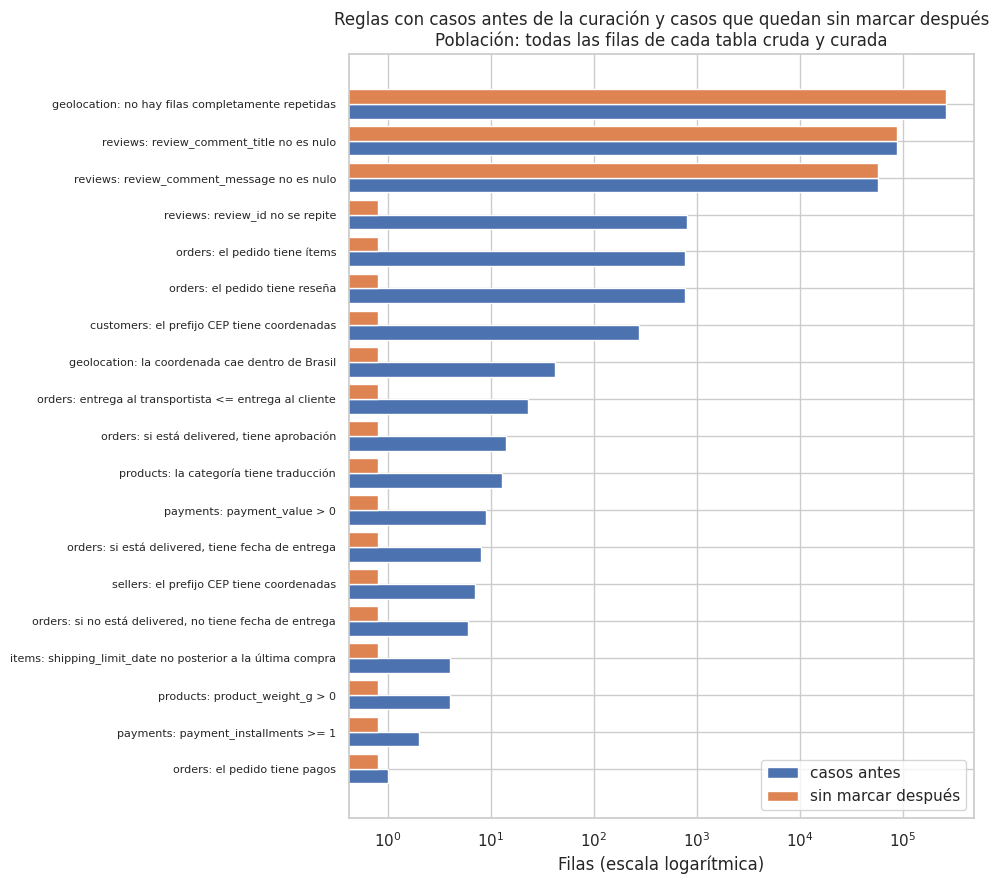

In [15]:
graf = cambios[cambios["casos_antes"].fillna(0) > 0].copy()
graf["etiqueta"] = graf["tabla"] + ": " + graf["regla"]
graf["sin marcar después"] = graf["sin_marcar_despues"].fillna(0)
graf = graf.sort_values("casos_antes")
fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(graf))
ax.barh(y - 0.2, graf["casos_antes"], height=0.4, label="casos antes")
ax.barh(y + 0.2, graf["sin marcar después"].clip(lower=0.8), height=0.4, label="sin marcar después")
ax.set_yticks(y, graf["etiqueta"], fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Filas (escala logarítmica)")
ax.set_title("Reglas con casos antes de la curación y casos que quedan sin marcar después\n"
             "Población: todas las filas de cada tabla cruda y curada")
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGS + "c1_10_antes_despues.png", dpi=150)
plt.show()

**Interpretación:** para cada regla con problemas, la barra de "después" muestra cuántas filas quedan sin una marca que las identifique (las barras en 1 indican cero, por la escala logarítmica). Salvo los comentarios de reseña y los duplicados de `geolocation`, todos los casos quedan corregidos o identificados. Ninguna fila de `orders` o `items` se eliminó: `pedidos` tiene 99.441 filas e `items` 112.650, igual que las fuentes.

## 8. Preguntas con el producto curado

### P1 y P2 con el producto curado

In [16]:
p1 = pedidos[pedidos["llego_tarde"].notna()]
por_estado = (p1.groupby("customer_state")
                .agg(pedidos=("order_id", "count"), pct_tarde=("llego_tarde", "mean"))
                .assign(pct_tarde=lambda d: d["pct_tarde"] * 100)
                .sort_values("pct_tarde", ascending=False))
por_estado["ic95"] = 1.96 * np.sqrt(por_estado["pct_tarde"] * (100 - por_estado["pct_tarde"]) / por_estado["pedidos"])
print("P1: población", len(p1), "pedidos;", round(p1["llego_tarde"].mean() * 100, 2), "% tarde en total")
p2 = p1[p1["review_score"].notna()]
print("P2:", p2.groupby("llego_tarde")["review_score"].agg(["count", "mean"]).round(2).to_dict())
por_estado.round(1).head(10)

P1: población 96470 pedidos; 6.77 % tarde en total
P2: {'count': {np.False_: 89443, np.True_: 6381}, 'mean': {np.False_: 4.29, np.True_: 2.27}}


,pedidos,pct_tarde,ic95
customer_state,,,
AL,397,21.4,4.0
MA,717,17.4,2.8
SE,335,15.2,3.8
PI,476,13.9,3.1
CE,1279,13.8,1.9
RR,41,12.2,10.0
BA,3256,12.2,1.1
RJ,12350,12.1,0.6
PA,946,11.2,2.0


### P3. ¿El valor pagado sirve para medir la facturación por categoría?

Población: ítems de pedidos `delivered` (grano ítem). Por D11 la métrica es `price`: el pago está a nivel de pedido e incluye intereses de cuotas. Para ver cuánto importa la decisión, comparamos con una alternativa: repartir el pago del pedido entre sus ítems en proporción al precio.

In [17]:
p3 = items_cur.merge(pedidos[["order_id", "order_status", "total_precio", "total_pagado", "pago_distinto_items"]],
                     on="order_id", how="left", validate="many_to_one")
p3 = p3[p3["order_status"] == "delivered"].copy()
p3["pago_asignado"] = p3["price"] / p3["total_precio"] * p3["total_pagado"]

por_categoria = (p3.groupby("categoria")
                   .agg(items=("order_item_id", "count"), facturacion_precio=("price", "sum"), pago_asignado=("pago_asignado", "sum"))
                   .sort_values("facturacion_precio", ascending=False))
por_categoria["pct_del_total"] = por_categoria["facturacion_precio"] / por_categoria["facturacion_precio"].sum() * 100
por_categoria["diferencia_pago_vs_precio_pct"] = (por_categoria["pago_asignado"] / por_categoria["facturacion_precio"] - 1) * 100
por_categoria["ranking_precio"] = np.arange(1, len(por_categoria) + 1)
por_categoria["ranking_pago"] = por_categoria["pago_asignado"].rank(ascending=False).astype(int)
print("Ítems:", len(p3), "| categorías:", len(por_categoria), "| facturación total por precio (BRL):", round(p3["price"].sum(), 2))
print("Categorías del top 10 que cambian de puesto si se usa el pago:",
      (por_categoria.head(10)["ranking_precio"] != por_categoria.head(10)["ranking_pago"]).sum())
por_categoria.head(15).round(2)

Ítems: 110197 | categorías: 74 | facturación total por precio (BRL): 13221498.11
Categorías del top 10 que cambian de puesto si se usa el pago: 1


,items,facturacion_precio,pago_asignado,pct_del_total,diferencia_pago_vs_precio_pct,ranking_precio,ranking_pago
categoria,,,,,,,
health_beauty,9465,1233131.72,1412140.48,9.33,14.52,1,1
watches_gifts,5859,1166176.98,1264697.30,8.82,8.45,2,2
bed_bath_table,10953,1023434.76,1225948.49,7.74,19.79,3,3
sports_leisure,8431,954852.55,1118166.98,7.22,17.10,4,4
computers_accessories,7644,888724.61,1032834.45,6.72,16.22,5,5
furniture_decor,8160,711927.69,880085.71,5.38,23.62,6,6
housewares,6795,615628.69,758384.53,4.66,23.19,7,7
cool_stuff,3718,610204.10,692011.60,4.62,13.41,8,8
auto,4140,578966.65,669363.86,4.38,15.61,9,9


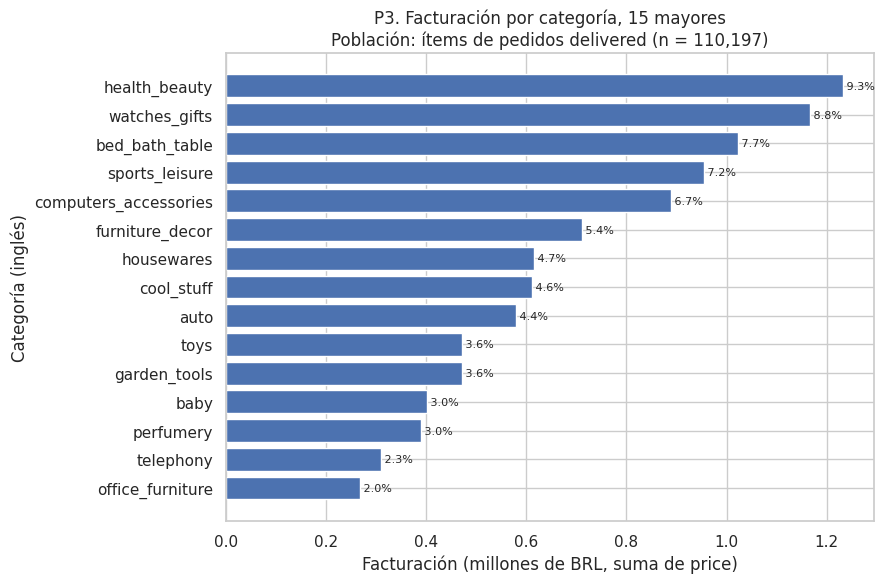

In [18]:
top = por_categoria.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["facturacion_precio"] / 1e6)
for y, (v, pct) in enumerate(zip(top["facturacion_precio"] / 1e6, top["pct_del_total"])):
    ax.text(v, y, f" {pct:.1f}%", va="center", fontsize=8)
ax.set_xlabel("Facturación (millones de BRL, suma de price)")
ax.set_ylabel("Categoría (inglés)")
ax.set_title(f"P3. Facturación por categoría, 15 mayores\nPoblación: ítems de pedidos delivered (n = {len(p3):,})")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "c1_11_facturacion_categoria.png", dpi=150)
plt.show()

**Interpretación:** sobre 110.197 ítems de pedidos entregados, las cinco categorías con más facturación (health_beauty, watches_gifts, bed_bath_table, sports_leisure y computers_accessories) suman el 39,8% del total de 13,2 millones de BRL. Si en lugar de `price` se reparte el pago del pedido entre sus ítems, cada una de las 15 mayores "factura" entre 8% y 25% más, porque el pago incluye flete e intereses de cuotas; sin embargo el orden del top 10 casi no cambia (solo toys y garden_tools intercambian los puestos 10 y 11). **Decisión:** P3 se responde que sí, pero con `price`: `payment_value` sirve para ordenar categorías y no para medir cuánto facturan (D11). **Qué no podemos concluir:** el margen de cada categoría, porque no hay costos; ni la facturación de los 610 productos `sin_categoria`, que se reportan aparte.

## 9. Desafío: datos que violan las reglas

Cada escenario parte de una copia de los productos curados, rompe una regla de forma controlada y corre `validar`. Incluimos escenarios que **no** deberían detectarse para mostrar los límites de los controles.

In [19]:
def escenario(nombre, regla, cambiar_pedidos=None, cambiar_items=None):
    ped, its = pedidos.copy(), items_cur.copy()
    if cambiar_pedidos:
        ped = cambiar_pedidos(ped)
    if cambiar_items:
        its = cambiar_items(its)
    fallas = validar(ped, its, n_orders=len(crudos["orders"]))
    return {"escenario": nombre, "regla que se viola": regla, "detectado": len(fallas) > 0,
            "controles que fallaron": "; ".join(sorted(set(fallas["control"].str.slice(0, 60)))) if len(fallas) else "-"}


def duplicar_pedido(df):
    return pd.concat([df, df.iloc[[0]]], ignore_index=True)


def puntaje_fuera_de_rango(df):
    df.loc[df.index[:5], "review_score"] = 6.0
    return df


def precio_negativo(df):
    df.loc[df.index[:3], "price"] = -10.0
    return df


def aprobacion_antes_de_compra(df):
    filas = df["order_approved_at"].notna()
    idx = df.index[filas][:4]
    df.loc[idx, "order_approved_at"] = df.loc[idx, "order_purchase_timestamp"] - pd.Timedelta(days=2)
    return df


def lat_lng_invertidas(df):
    idx = df.index[df["cliente_lat"].notna()][:10]
    df.loc[idx, ["cliente_lat", "cliente_lng"]] = df.loc[idx, ["cliente_lng", "cliente_lat"]].values
    return df


def borrar_pedido(df):
    return df.drop(df.index[df["n_items"] > 0][:1])


def fecha_como_texto(df):
    df["order_purchase_timestamp"] = df["order_purchase_timestamp"].astype(str)
    return df


def puntaje_valido_pero_falso(df):
    df.loc[df["review_score"] == 5, "review_score"] = 1.0
    return df


def tarde_invertido(df):
    df["llego_tarde"] = ~df["llego_tarde"]
    return df


def precio_inflado(df):
    df["price"] = df["price"] * 10
    return df


resultado_desafio = pd.DataFrame([
    escenario("pedido duplicado", "unicidad de order_id", cambiar_pedidos=duplicar_pedido),
    escenario("puntaje 6", "review_score en {1..5}", cambiar_pedidos=puntaje_fuera_de_rango),
    escenario("precio negativo", "price > 0", cambiar_items=precio_negativo),
    escenario("aprobación 2 días antes de la compra", "compra <= aprobación", cambiar_pedidos=aprobacion_antes_de_compra),
    escenario("latitud y longitud invertidas", "coordenadas dentro de Brasil", cambiar_pedidos=lat_lng_invertidas),
    escenario("se pierde un pedido con ítems", "integridad pedidos/items", cambiar_pedidos=borrar_pedido),
    escenario("fecha leída como texto", "tipos del contrato", cambiar_pedidos=fecha_como_texto),
    escenario("todos los 5 pasan a 1", "ninguna (valor válido pero falso)", cambiar_pedidos=puntaje_valido_pero_falso),
    escenario("llego_tarde invertido", "ninguna (incoherente con dias_vs_estimado)", cambiar_pedidos=tarde_invertido),
    escenario("precios multiplicados por 10", "ninguna (cambio de escala)", cambiar_items=precio_inflado),
])
resultado_desafio.to_csv(RUTA_REPORTS + "desafio_controles.csv", index=False)
resultado_desafio

,escenario,regla que se viola,detectado,controles que fallaron
0,pedido duplicado,unicidad de order_id,True,cantidad de pedidos distinta de orders; field_...
1,puntaje 6,review_score en {1..5},True,"isin([1, 2, 3, 4, 5])"
2,precio negativo,price > 0,True,greater_than(0)
3,aprobación 2 días antes de la compra,compra <= aprobación,True,order_purchase_timestamp <= order_approved_at
4,latitud y longitud invertidas,coordenadas dentro de Brasil,True,"in_range(-33.75, 5.3); in_range(-73.99, -34.79)"
5,se pierde un pedido con ítems,integridad pedidos/items,True,cantidad de pedidos distinta de orders; items ...
6,fecha leída como texto,tipos del contrato,True,dtype('datetime64[ns]'); in_range(2016-01-01 0...
7,todos los 5 pasan a 1,ninguna (valor válido pero falso),False,-
8,llego_tarde invertido,ninguna (incoherente con dias_vs_estimado),False,-
9,precios multiplicados por 10,ninguna (cambio de escala),False,-


In [20]:
try:
    exigir(puntaje_fuera_de_rango(pedidos.copy()), items_cur, n_orders=len(crudos["orders"]))
except ValueError as error:
    print(str(error)[:600])

El dataset curado no cumple el contrato:
  tabla      columna               control  casos
pedidos review_score isin([1, 2, 3, 4, 5])      5


**Interpretación:** los siete escenarios que violan reglas del contrato se detectan, y la tabla muestra qué control falló en cada uno. Un pedido duplicado lo detectan tres controles a la vez (unicidad, cantidad de filas y coherencia con los ítems), y un pedido perdido lo detecta la integridad entre productos aunque `pedidos` siga siendo válido por sí solo. Los tres últimos escenarios **no** se detectan, y es esperable: un 5 cambiado por 1 sigue siendo un puntaje válido; `llego_tarde` invertido no rompe ninguna regla porque el contrato no la recalcula a partir de `dias_vs_estimado`; y multiplicar todos los precios por 10 mantiene precios positivos. Para los dos últimos harían falta controles de otro tipo: una regla que recalcule la columna derivada y un control estadístico que compare la distribución con una referencia (por ejemplo, mediana del precio dentro de un rango).

## 10. Registro de decisiones

| ID | Decisión (alternativa descartada) | Justificación | Filas afectadas | Estado |
|---|---|---|---|---|
| D01 | Los CSV quedan en `data/raw/` sin editar ni subir; lo curado va a `data/curated/` (trabajar sobre los CSV) | La consigna exige no sobrescribir la fuente | Ninguna | Firme |
| D02 | Prefijos de CEP como texto (dejar el tipo que infiere pandas) | Son códigos: como número pierden los ceros iniciales | Clientes, vendedores y geolocation | Firme |
| D03 | Fechas con `to_datetime(errors="coerce")` y un `assert` que falla si aparecen nulos nuevos (convertir sin controlar) | Un valor inválido no puede volverse nulo en silencio | 0 valores no convertidos | Firme |
| D04 | Dos productos: `pedidos` (grano pedido) e `items` (grano ítem) (un único producto a nivel ítem) | La reseña es del pedido (4,086 por pedido vs 4,033 por ítem); P3 necesita la categoría, que es del ítem | 99.441 y 112.650 filas | Firme |
| D05 | Reseña más reciente por pedido, desempate por fecha de respuesta (promedio, peor puntaje o excluir) | Las cinco reglas dan diferencias menores a 0,003 en el promedio (sección 3) | 551 reseñas no elegidas; 547 pedidos marcados | Firme |
| D06 | Integrar `sellers` y `geolocation` (dejarlas fuera, como en el avance) | La devolución lo pide y el Caso 2 necesita ubicar a clientes y vendedores | Todas las filas de `items` y `pedidos` | Firme |
| D07 | Marcar pedidos sin ítems, pago o reseña (borrarlos) | Son en su mayoría ausencias con significado (unavailable, canceled, reseña voluntaria) | 775, 1 y 768 pedidos | Firme |
| D08 | P1 y P2 solo sobre `delivered` con fecha de entrega (todos los pedidos con fecha) | 8 delivered sin fecha y 6 no entregados con fecha | 96.470 pedidos en P1; 95.824 en P2 | Firme |
| D09 | Indicador `en_periodo_mensual` para enero 2017 a agosto 2018 (usar todo el período) | 2016 y setiembre-octubre 2018 tienen cobertura incompleta | 349 pedidos fuera del período | Firme |
| D10 | Traducir a mano 2 categorías y etiquetar `sin_categoria` (dejar nulos o descartar) | 13 productos sin traducción y 610 sin categoría | 623 productos | Firme |
| D11 | Facturación con `price`, no con `payment_value` (usar el pago) | El pago incluye intereses y está a nivel pedido; asignado a ítems infla 8–25% por categoría (sección 8) | Define la métrica; 249 pedidos marcados | Firme |
| D12 | Marcar entrega al transportista posterior a la entrega al cliente, sin corregir la fecha (poner la fecha en nulo) | No sabemos cuál de las dos fechas está mal | 23 pedidos | Firme |
| D13 | Marcar pagos de valor 0 y pasar 0 cuotas a 1 (descartar esos pagos) | Los vouchers en 0 son eventos reales; 0 cuotas no existe en un pago con tarjeta | 9 y 2 pagos | Firme |
| D14 | Peso 0 pasa a nulo y se marca (dejarlo en 0) | Un producto no puede pesar 0 g | 4 productos | Firme |
| D15 | Fecha límite de envío posterior a la última compra pasa a nulo y se marca (dejarla) | Fechas en 2020 para pedidos de 2017 | 4 ítems | Firme |
| D16 | Marcar no entregados con fecha de entrega y delivered sin aprobación (corregir el estado) | No hay evidencia para saber el estado real | 6 y 14 pedidos | Firme |
| D17 | Coordenadas: descartar puntos fuera de Brasil y usar la mediana por prefijo; marcar prefijos sin coordenadas (media por prefijo; primer punto) | Robusta ante puntos mal ubicados (sección 4) | 42 puntos; 279 clientes y 7 vendedores sin coordenadas (253 ítems) | Firme |
| D18 | Contrato Pandera en `src/contratos.py` y `exigir` antes de guardar (validar a mano en el notebook) | Los controles deben poder fallar y ser reutilizables en el Caso 2 | Todo el producto | Firme |

## 11. Conclusiones: qué usos habilita el dataset

**Usos que habilita** (con el producto curado y sus indicadores):

- Comparar el porcentaje de entregas tarde entre estados (P1) en los que tienen suficientes pedidos: SP, RJ, MG, BA y la mayoría del nordeste tienen intervalos de ±0,6 a ±4 puntos, alcanzan para priorizar AL, MA, SE, PI y CE.
- Usar el puntaje de la reseña como señal de satisfacción con la entrega (P2), de forma descriptiva: la diferencia de unos 2 puntos entre a tiempo y tarde es estable ante la regla de reseñas repetidas.
- Ordenar categorías por facturación con `price` (P3).
- Series mensuales de pedidos de enero 2017 a agosto 2018.

**Usos que exigen revisión adicional:**

- Ordenar estados con pocos pedidos (RR con 41 pedidos tiene un intervalo de ±10 puntos; también AP y AC).
- Tiempos de tránsito: 23 pedidos tienen fechas en orden imposible y no podemos verificar la exactitud del resto.
- Análisis espaciales finos: las coordenadas son la mediana del prefijo de CEP, no la dirección; 279 clientes no tienen coordenadas.
- Cualquier análisis de los comentarios de reseña: faltan en el 58,7% y la ausencia depende del puntaje.

**Usos que no recomendamos con esta evidencia:**

- Afirmar que la demora **causa** el puntaje bajo: hay otros factores (producto, vendedor) no controlados.
- Medir facturación o ticket promedio con `payment_value`.
- Analizar 2016 o setiembre-octubre de 2018 como meses comparables al resto.
- Inferir la satisfacción de los 646 pedidos entregados sin reseña o generalizar los resultados a todo el e-commerce brasileño: es un solo marketplace.

## 12. Uso de IA

Secuencia del curso: predecir, intentar, consultar, verificar y declarar. No se compartieron con la IA datos sensibles, credenciales ni información personal.

| Fecha | Integrante | Herramienta | Para qué | Qué produjo | Qué modificamos | Cómo lo validamos |
|---|---|---|---|---|---|---|
| 22-08 | Bruno | Claude Opus 5 | Planificar el avance y armar el esqueleto del repositorio | Estructura del repo y esqueleto del notebook del avance | Quitamos bloques redundantes | Ejecutamos el notebook bloque a bloque |
| 11-09 | Juan Pablo Esteva | Claude Opus 5 | Redacción de documentos del avance | Textos corregidos | Vocabulario, tablas y estilo | Comparación punto a punto con la información que teníamos |
| 22-11 | Juan Pablo Esteva | Claude (Opus 5.5) | Implementar la curación, el contrato Pandera, el perfil antes/después y el desafío a partir de la devolución | Este notebook y `src/contratos.py` | COMPLETAR | Ejecutamos el notebook de principio a fin; COMPLETAR |